
# Synthetic Vehicle Insurance Fraud Dataset

**Generator + exploratory data analysis (EDA), Google Colab ready.**

This notebook builds a reproducible synthetic dataset of vehicle insurance claims with a deliberately hard fraud signal, then explores it. It does **not** train a production model.

## Read this before using any number from this notebook

- The data is **synthetic**. A model can only recover the rules that were planted here. High metrics prove that the pipeline works, not that fraud can be detected in the real world.
- If you quote a metric in a CV or report, always label it **"on synthetic data"**.
- The fraud mechanism is a logistic probability model with noise, label noise, missingness, dirty records, and a time-based drift. It is intentionally not a clean `if/else` rule set.
- The generator configuration is **locked** in this notebook. The target difficulty ranges are diagnostics, not something to tune against after looking at results.
- `true_fraud` and the fraud probability are stored in a separate truth file for analysis only. The modelling table exposes only `is_fraud`.

## What is inside

1. Design summary and honest assumptions
2. Setup, locked configuration, reproducibility helpers
3. Reference tables: workshops, customers, policies
4. Claims table and derived risk features used only inside the generator
5. Fraud probability model and label noise
6. Post-processing leakage columns
7. Deliberate imperfections and Parquet export
8. Loading and rebuilding pipeline features
9. EDA: missingness, class balance, univariate lift, workshops, leakage, drift, fairness, data quality
10. Optional appendix: a fixed-config difficulty diagnostic (no tuning)
11. Limitations, next steps, reproducibility

## Runtime

Runtime > Run all. On a standard Colab CPU runtime the generation and EDA should finish in a couple of minutes. No external data or API key is required.

## Output layout

```
data/
  README.md                    # English documentation
  README.id.md                 # Indonesian documentation
  customers.parquet
  policies.parquet
  claims.parquet
  workshops.parquet
  claims_features.parquet      # created by the feature-building cell
  claims_truth.parquet         # analysis only, never join into model features
  generator_config.json
  manifest.json
  notebooks/
    vehicle_insurance_fraud_synth.ipynb   # generator + inline EDA
    eda_vehicle_insurance_fraud.ipynb     # read-only EDA
```



## 1. Design summary and honest assumptions

| Table | Rows | Grain |
|---|---:|---|
| `customers` | 80,000 | one customer |
| `policies` | 100,000 | one policy; 1 or 2 per customer |
| `claims` | ~150,000 | one claim; the modelling table |
| `workshops` | 304 | 300 base workshops + 4 opened in 2025 for the drift story |

**Period:** 2021-01-01 to 2025-12-31. **Latent fraud rate:** 3.5%. **Observed label rate:** about 3.0% because 15% of fraudulent claims are never detected and are labelled 0.

Assumptions that are deliberately unrealistic:

- About 1.5 claims per policy is too high for private motor insurance. Claim frequency and exposure are not modelled; this is a claim-level fraud dataset, not a frequency model.
- Vehicle values, premiums, and claim amounts are plausible-looking IDR numbers, not actuarial rates.
- Geography, occupations, and workshop names are synthetic labels, not a real portfolio.
- Detection is a single fixed probability. Real investigation is selective and biased.
- The 2025 drift is planted, not estimated from history.

**Fairness warning:** `age` and `province` are not used to generate fraud, but they exist in the tables. If you put them into a fraud model, the result can be read as discriminatory profiling. Either exclude them from model features or discuss the choice explicitly in a model card. The optional diagnostic at the end excludes both.



## 2. Setup and locked configuration

Every generator parameter lives in the dictionary below. Treat it as frozen. If you change an effect after seeing EDA or model results, you are tuning the data generator to the evaluation, and the result stops being an honest benchmark.


In [1]:

import hashlib
import json
import platform
import sys
import warnings
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 120)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")
sns.set_theme(style="whitegrid", context="notebook")

CONFIG = {
    "seed": 20261028,
    "n_customers": 80_000,
    "n_claims": 150_000,
    "policy_start_latest": "2025-09-30",
    "period": {"start": "2021-01-01", "end": "2025-12-31"},
    "policies": {
        "share_two_policies": 0.25,
        "vehicle_type_probs": {
            "motorcycle": 0.46,
            "private_car": 0.40,
            "commercial_vehicle": 0.09,
            "truck": 0.05,
        },
    },
    "workshops": {
        "n_base": 300,
        "n_new_2025": 4,
        "old_ring_size": 10,
        "authorized_share": 0.55,
        "old_ring_weight_pre2025": 2.2,
        "old_ring_weight_2025": 1.0,
        "new_ring_weight_2025": 3.0,
    },
    "fraud": {
        "target_prevalence_true": 0.035,
        "logit_noise_sd": 1.05,
        "detection_rate": 0.85,
        "effects": {
            "early_claim_60d": 3.0,
            "report_delay_gt_14d": 2.0,
            "theft_no_police_report": 4.0,
            "claim_ratio_gt_0_8": 2.5,
            "prior_claims_12m_ge_3": 2.0,
            "incident_hour_0_4": 1.5,
            "non_authorized_workshop": 1.5,
            "overvaluation": 2.0,
            "online_new_customer": 1.8,
            "early_x_large_claim": 1.5,
        },
        "ring_odds": {
            "old_ring_pre2025": 6.5,
            "old_ring_2025": 2.2,
            "new_ring_2025": 7.5,
        },
        "online_effect_2025_multiplier": 1.55,
    },
    "missing": {
        "witness_count": {"base": 0.05, "fraud": 0.14},
        "police_report_filed": {"base": 0.04, "fraud": 0.12},
        "incident_hour": {"base": 0.05, "fraud": 0.13},
    },
    "dirty": {
        "category_variant_rate": 0.03,
        "negative_report_delay_rate": 0.003,
        "claim_amount_outlier_rate": 0.005,
        "duplicate_rate": 0.002,
    },
    "splits": {
        "train_end": "2023-12-31",
        "valid_end": "2024-06-30",
        "test_start": "2024-07-01",
    },
}


def rng_for(part: str) -> np.random.Generator:
    digest = hashlib.sha256(f"{CONFIG['seed']}:{part}".encode("utf-8")).hexdigest()
    return np.random.default_rng(int(digest[:8], 16))


def sigmoid(value):
    return 1.0 / (1.0 + np.exp(-np.clip(value, -35.0, 35.0)))


def day_number(value) -> int:
    return (pd.Timestamp(value) - pd.Timestamp("1970-01-01")).days


def from_day_number(days):
    return pd.Timestamp("1970-01-01") + pd.to_timedelta(np.asarray(days), unit="D")


def resolve_data_dir() -> Path:
    # Local runs resolve to the repository data/ folder; Colab uses /content/data.
    if Path("/content").exists():
        return Path("/content/data")
    here = Path.cwd().resolve()
    for candidate in (here, *here.parents):
        if candidate.name == "data" and (candidate / "notebooks").is_dir():
            return candidate
        if (candidate / "data" / "notebooks").is_dir():
            return candidate / "data"
    return here / "data"


DATA_DIR = resolve_data_dir()
TRUTH_DIR = DATA_DIR
DATA_DIR.mkdir(parents=True, exist_ok=True)

START = pd.Timestamp(CONFIG["period"]["start"])
END = pd.Timestamp(CONFIG["period"]["end"])
START_DAY = day_number(START)
END_DAY = day_number(END)

print(f"Python {platform.python_version()} | numpy {np.__version__} | pandas {pd.__version__}")
print(f"Output directory: {DATA_DIR}")
print(json.dumps(CONFIG, indent=2))


Python 3.13.18 | numpy 2.1.3 | pandas 2.2.3
Output directory: /content/vehicle_fraud_synth
{
  "seed": 20261028,
  "n_customers": 80000,
  "n_claims": 150000,
  "policy_start_latest": "2025-09-30",
  "period": {
    "start": "2021-01-01",
    "end": "2025-12-31"
  },
  "policies": {
    "share_two_policies": 0.25,
    "vehicle_type_probs": {
      "motorcycle": 0.46,
      "private_car": 0.4,
      "commercial_vehicle": 0.09,
      "truck": 0.05
    }
  },
  "workshops": {
    "n_base": 300,
    "n_new_2025": 4,
    "old_ring_size": 10,
    "authorized_share": 0.55,
    "old_ring_weight_pre2025": 2.2,
    "old_ring_weight_2025": 1.0,
    "new_ring_weight_2025": 3.0
  },
  "fraud": {
    "target_prevalence_true": 0.035,
    "logit_noise_sd": 1.05,
    "detection_rate": 0.85,
    "effects": {
      "early_claim_60d": 3.0,
      "report_delay_gt_14d": 2.0,
      "theft_no_police_report": 4.0,
      "claim_ratio_gt_0_8": 2.5,
      "prior_claims_12m_ge_3": 2.0,
      "incident_hour_0_4": 1

In [2]:

# Reference geography. Weights are synthetic and only shape volume.
PROVINCE_TABLE = pd.DataFrame({
    "province": [
        "DKI Jakarta", "Jawa Barat", "Jawa Timur", "Jawa Tengah",
        "Banten", "Sumatera Utara", "Bali", "DI Yogyakarta",
        "Sumatera Selatan", "Sulawesi Selatan", "Sumatera Barat",
        "Kalimantan Timur",
    ],
    "weight": [
        0.18, 0.17, 0.14, 0.12, 0.08, 0.07, 0.05, 0.05, 0.04, 0.04, 0.03, 0.03,
    ],
})
PROVINCE_TABLE["weight"] = PROVINCE_TABLE["weight"] / PROVINCE_TABLE["weight"].sum()
PROVINCE_LIST = PROVINCE_TABLE["province"].tolist()
PROVINCE_WEIGHTS = PROVINCE_TABLE["weight"].to_numpy()

CITIES = {
    "DKI Jakarta": ["Jakarta Pusat", "Jakarta Selatan", "Jakarta Barat", "Jakarta Timur", "Jakarta Utara"],
    "Jawa Barat": ["Bandung", "Bekasi", "Depok", "Bogor", "Cimahi"],
    "Jawa Timur": ["Surabaya", "Malang", "Sidoarjo", "Kediri"],
    "Jawa Tengah": ["Semarang", "Solo", "Magelang", "Kudus"],
    "Banten": ["Tangerang", "Serang", "Cilegon"],
    "Sumatera Utara": ["Medan", "Binjai", "Deli Serdang"],
    "Bali": ["Denpasar", "Badung", "Gianyar"],
    "DI Yogyakarta": ["Yogyakarta", "Sleman", "Bantul"],
    "Sumatera Selatan": ["Palembang", "Lubuklinggau"],
    "Sulawesi Selatan": ["Makassar", "Parepare"],
    "Sumatera Barat": ["Padang", "Bukittinggi"],
    "Kalimantan Timur": ["Samarinda", "Balikpapan"],
}

OCCUPATIONS = [
    "employee", "self_employed", "professional", "entrepreneur",
    "civil_servant", "student", "retired", "other",
]
OCCUPATION_PROBS = [0.35, 0.20, 0.12, 0.10, 0.08, 0.06, 0.05, 0.04]

INCIDENT_TYPES = ["collision", "theft", "flood", "vandalism", "fire"]
INCIDENT_TYPE_PROBS = {
    "motorcycle": [0.50, 0.24, 0.08, 0.10, 0.08],
    "private_car": [0.58, 0.10, 0.12, 0.10, 0.10],
    "commercial_vehicle": [0.60, 0.08, 0.12, 0.08, 0.12],
    "truck": [0.62, 0.10, 0.10, 0.05, 0.13],
}

display(PROVINCE_TABLE)


,province,weight
0,DKI Jakarta,0.1800
1,Jawa Barat,0.1700
2,Jawa Timur,0.1400
3,Jawa Tengah,0.1200
4,Banten,0.0800
5,Sumatera Utara,0.0700
6,Bali,0.0500
7,DI Yogyakarta,0.0500
8,Sumatera Selatan,0.0400
9,Sulawesi Selatan,0.0400



## 3. Workshops

304 workshops: 300 base workshops plus 4 opened on 2025-01-01. Ten base workshops are a hidden fraud ring. In 2025 the old ring is dampened and the new workshops take over part of the ring behaviour. Neither ring membership nor the truth flag is written to `workshops.parquet`.


In [3]:

rng = rng_for("workshops")
n_base = CONFIG["workshops"]["n_base"]
n_new = CONFIG["workshops"]["n_new_2025"]
n_workshops = n_base + n_new

raw_alloc = PROVINCE_WEIGHTS * n_base
alloc = np.floor(raw_alloc).astype(int)
remainder = n_base - int(alloc.sum())
alloc[np.argsort(-(raw_alloc - alloc))[:remainder]] += 1

workshop_province = np.repeat(np.array(PROVINCE_LIST, dtype=object), alloc)
new_provinces = PROVINCE_LIST[:n_new]
workshop_province = np.concatenate([workshop_province, np.array(new_provinces, dtype=object)])

workshop_city = np.array([rng.choice(CITIES[province]) for province in workshop_province], dtype=object)

prefixes = ["Sumber", "Jaya", "Maju", "Berkah", "Prima", "Sentosa", "Karya", "Mitra", "Andalan", "Cahaya"]
suffixes = ["Motor", "Auto", "Body Repair", "Service", "Teknik", "Otomotif"]
raw_names = [f"{rng.choice(prefixes)} {rng.choice(suffixes)} {city}" for city in workshop_city]
seen = {}
workshop_name = []
for name in raw_names:
    if name in seen:
        seen[name] += 1
        workshop_name.append(f"{name} {seen[name]}")
    else:
        seen[name] = 1
        workshop_name.append(name)

base_open = rng.integers(day_number("2010-01-01"), day_number("2020-12-31"), size=n_base)
new_open = np.full(n_new, day_number("2025-01-01"))
opened_days = np.concatenate([base_open, new_open])
is_authorized = (rng.random(n_workshops) < CONFIG["workshops"]["authorized_share"]).astype(int)

workshops = pd.DataFrame({
    "workshop_id": [f"W{i:04d}" for i in range(1, n_workshops + 1)],
    "workshop_name": workshop_name,
    "province": workshop_province,
    "city": workshop_city,
    "is_authorized_workshop": is_authorized,
    "opened_date": from_day_number(opened_days),
})

base_ids = workshops.loc[workshops["opened_date"] < pd.Timestamp("2025-01-01"), "workshop_id"].to_numpy()
old_ring_ids = rng.choice(base_ids, size=CONFIG["workshops"]["old_ring_size"], replace=False)
new_ring_ids = workshops.loc[workshops["opened_date"] == pd.Timestamp("2025-01-01"), "workshop_id"].to_numpy()

WORKSHOP_RING = {}
for workshop_id in old_ring_ids:
    WORKSHOP_RING[workshop_id] = "old"
for workshop_id in new_ring_ids:
    WORKSHOP_RING[workshop_id] = "new"

WORKSHOP_IDS = workshops["workshop_id"].to_numpy()
W_PROV = workshops["province"].to_numpy()
W_OPEN = workshops["opened_date"].map(day_number).to_numpy()
W_RING = workshops["workshop_id"].map(WORKSHOP_RING).fillna("").to_numpy()
W_OLD = W_RING == "old"
W_NEW = W_RING == "new"
W_PRE = W_OPEN < day_number("2025-01-01")
AUTH_MAP = workshops.set_index("workshop_id")["is_authorized_workshop"]

print(f"Workshops: {len(workshops):,} | base: {n_base} | opened 2025: {n_new}")
print(f"Hidden ring: {len(old_ring_ids)} old + {len(new_ring_ids)} new")
print(workshops["province"].value_counts().head(8))
display(workshops.head())


Workshops: 304 | base: 300 | opened 2025: 4
Hidden ring: 10 old + 4 new
province
DKI Jakarta       55
Jawa Barat        52
Jawa Timur        43
Jawa Tengah       37
Banten            24
Sumatera Utara    21
Bali              15
DI Yogyakarta     15
Name: count, dtype: int64


,workshop_id,workshop_name,province,city,is_authorized_workshop,opened_date
0,W0001,Prima Motor Jakarta Utara,DKI Jakarta,Jakarta Utara,0,2012-01-05
1,W0002,Cahaya Otomotif Jakarta Barat,DKI Jakarta,Jakarta Barat,1,2017-10-21
2,W0003,Berkah Body Repair Jakarta Barat,DKI Jakarta,Jakarta Barat,0,2017-12-09
3,W0004,Sentosa Motor Jakarta Timur,DKI Jakarta,Jakarta Timur,1,2016-05-31
4,W0005,Berkah Teknik Jakarta Timur,DKI Jakarta,Jakarta Timur,1,2016-01-07



## 4. Customers and policies

Customers are generated first, policies second, and `customer_since` is back-calculated so that every policy starts after the customer relationship began. This gives a consistent tenure feature and creates genuinely new customers for the `online + tenure < 6 months` signal.


In [4]:

rng = rng_for("customers")
n_customers = CONFIG["n_customers"]
customer_ids = np.array([f"C{i:06d}" for i in range(1, n_customers + 1)])

age = np.clip(np.rint(rng.normal(38, 12, n_customers)), 18, 75).astype(int)
occupation = rng.choice(OCCUPATIONS, size=n_customers, p=OCCUPATION_PROBS)
province = rng.choice(PROVINCE_LIST, size=n_customers, p=PROVINCE_WEIGHTS)

rng = rng_for("policies")
n_two = int(round(n_customers * CONFIG["policies"]["share_two_policies"]))
policy_counts = np.ones(n_customers, dtype=np.int8)
policy_counts[rng.choice(n_customers, size=n_two, replace=False)] = 2
policy_customer = np.repeat(customer_ids, policy_counts)
n_policies = len(policy_customer)
assert n_policies == 100_000, n_policies

latest_start_day = day_number(CONFIG["policy_start_latest"])
start_days = rng.integers(START_DAY, latest_start_day + 1, size=n_policies)
start_dates = from_day_number(start_days)

vehicle_type_probs = CONFIG["policies"]["vehicle_type_probs"]
vehicle_types = list(vehicle_type_probs.keys())
vehicle_type = rng.choice(vehicle_types, size=n_policies, p=list(vehicle_type_probs.values()))

vehicle_age = np.empty(n_policies)
age_scale = {
    "motorcycle": 2.4,
    "private_car": 3.2,
    "commercial_vehicle": 4.0,
    "truck": 4.5,
}
for vehicle in vehicle_types:
    mask = vehicle_type == vehicle
    vehicle_age[mask] = rng.gamma(2.0, age_scale[vehicle], size=int(mask.sum()))
vehicle_age = np.clip(np.rint(vehicle_age), 0, 25).astype(int)

value_spec = {
    "motorcycle": (28_000_000, 0.45, 4_000_000, 150_000_000),
    "private_car": (260_000_000, 0.55, 30_000_000, 2_000_000_000),
    "commercial_vehicle": (420_000_000, 0.60, 60_000_000, 3_000_000_000),
    "truck": (650_000_000, 0.65, 80_000_000, 4_000_000_000),
}
vehicle_value = np.empty(n_policies)
for vehicle, (median, sigma, lower, upper) in value_spec.items():
    mask = vehicle_type == vehicle
    draws = rng.lognormal(np.log(median), sigma, size=int(mask.sum()))
    vehicle_value[mask] = np.clip(draws, lower, upper)
vehicle_value = np.round(vehicle_value / 100_000) * 100_000

sum_insured = np.round(vehicle_value * rng.uniform(0.85, 1.15, n_policies) / 100_000) * 100_000
sum_insured = np.maximum(sum_insured, 1_000_000)

coverage_type = np.empty(n_policies, dtype=object)
for vehicle in vehicle_types:
    mask = vehicle_type == vehicle
    if vehicle == "motorcycle":
        probs = [0.38, 0.62]
    else:
        probs = [0.72, 0.28]
    coverage_type[mask] = rng.choice(["Comprehensive", "TLO"], size=int(mask.sum()), p=probs)

start_year = start_dates.year.to_numpy()
online_prob = np.clip(0.25 + 0.04 * (start_year - 2021), 0.25, 0.45)
is_online = rng.random(n_policies) < online_prob
sales_channel = np.empty(n_policies, dtype=object)
sales_channel[is_online] = "online"
not_online = ~is_online
sales_channel[not_online] = rng.choice(["agent", "broker"], size=int(not_online.sum()), p=[0.70, 0.30])

payment_frequency = np.empty(n_policies, dtype=object)
online_freq = ["annual", "semiannual", "quarterly", "monthly"]
payment_frequency[is_online] = rng.choice(online_freq, size=int(is_online.sum()), p=[0.35, 0.20, 0.20, 0.25])
payment_frequency[not_online] = rng.choice(online_freq, size=int(not_online.sum()), p=[0.65, 0.18, 0.12, 0.05])

base_rate = np.where(coverage_type == "Comprehensive", 0.032, 0.011)
channel_factor = np.where(sales_channel == "agent", 1.00, np.where(sales_channel == "broker", 1.06, 0.90))
age_factor = 1.0 + 0.025 * vehicle_age
premium_noise = rng.lognormal(0.0, 0.10, size=n_policies)
annual_premium = sum_insured * base_rate * age_factor * channel_factor * premium_noise
annual_premium = np.maximum(annual_premium, 180_000)
annual_premium = np.round(annual_premium / 10_000) * 10_000

policies = pd.DataFrame({
    "policy_id": [f"P{i:07d}" for i in range(1, n_policies + 1)],
    "customer_id": policy_customer,
    "policy_start_date": start_dates,
    "policy_end_date": from_day_number(start_days + 365),
    "coverage_type": coverage_type,
    "vehicle_type": vehicle_type,
    "vehicle_age_years": vehicle_age,
    "vehicle_value": vehicle_value,
    "sum_insured": sum_insured,
    "annual_premium": annual_premium,
    "sales_channel": sales_channel,
    "payment_frequency": payment_frequency,
})

first_start = policies.groupby("customer_id")["policy_start_date"].min().reindex(customer_ids)
first_start_days = first_start.map(day_number).to_numpy()
tenure_before_months = rng.choice(
    [3, 12, 36, 84, 180],
    size=n_customers,
    p=[0.35, 0.25, 0.20, 0.12, 0.08],
)
tenure_before_days = np.maximum(
    0.0,
    (tenure_before_months + rng.uniform(-2.0, 2.0, size=n_customers)) * 30.44,
).astype(int)
customer_since_days = first_start_days - tenure_before_days

customers = pd.DataFrame({
    "customer_id": customer_ids,
    "age": age,
    "occupation_group": occupation,
    "province": province,
    "customer_since": from_day_number(customer_since_days),
    "customer_tenure_months": np.maximum(
        0, np.rint((END_DAY - customer_since_days) / 30.44)
    ).astype(int),
    "n_policies_total": policy_counts,
})

print(f"Customers: {len(customers):,} | Policies: {len(policies):,}")
display(customers.head())
display(policies.head())


Customers: 80,000 | Policies: 100,000


,customer_id,age,occupation_group,province,customer_since,customer_tenure_months,n_policies_total
0,C000001,18,employee,Jawa Tengah,2021-05-09,56,1
1,C000002,30,self_employed,DKI Jakarta,2025-03-16,10,1
2,C000003,43,self_employed,Jawa Timur,2016-04-10,117,2
3,C000004,56,employee,Jawa Barat,2014-02-12,143,1
4,C000005,23,entrepreneur,Jawa Barat,2007-05-31,223,2


,policy_id,customer_id,policy_start_date,policy_end_date,coverage_type,vehicle_type,vehicle_age_years,vehicle_value,sum_insured,annual_premium,sales_channel,payment_frequency
0,P0000001,C000001,2021-08-13,2022-08-13,Comprehensive,private_car,15,"327,900,000.0000","339,200,000.0000","13,700,000.0000",agent,semiannual
1,P0000002,C000002,2025-07-22,2026-07-22,TLO,private_car,8,"309,700,000.0000","304,300,000.0000","4,440,000.0000",agent,annual
2,P0000003,C000003,2023-08-04,2024-08-03,Comprehensive,private_car,4,"119,200,000.0000","124,500,000.0000","3,720,000.0000",agent,annual
3,P0000004,C000003,2023-03-25,2024-03-24,TLO,motorcycle,2,"56,400,000.0000","60,100,000.0000","750,000.0000",broker,annual
4,P0000005,C000004,2021-04-11,2022-04-11,Comprehensive,private_car,13,"158,300,000.0000","157,300,000.0000","5,610,000.0000",online,semiannual



## 5. Claims table

Claims are assigned to policies, then dated inside the policy year. Claim frequency is **not** modelled: assigning 150,000 claims across 100,000 policies gives roughly 1.5 claims per policy, which is unrealistic for motor insurance and is stated as an assumption.

The generator uses derived risk features internally (`early claim`, `report delay`, `claim / sum insured`, `prior claims`, `workshop activity`) to build the fraud probability. Those features are not written into the raw `claims.parquet`. They are rebuilt by the EDA feature pipeline, which makes the separation between generator and pipeline explicit.


In [5]:

rng = rng_for("claims")
n_claims = CONFIG["n_claims"]
policy_idx = rng.integers(0, n_policies, size=n_claims)

claim_customer = policy_customer[policy_idx]
claim_start_days = start_days[policy_idx]
claim_sum_insured = sum_insured[policy_idx]
claim_vehicle_type = vehicle_type[policy_idx]

max_offset = np.minimum(364, END_DAY - claim_start_days)
offset = (rng.random(n_claims) * (max_offset + 1)).astype(int)
incident_days = claim_start_days + offset
incident_dates = from_day_number(incident_days)
incident_year = incident_dates.year.to_numpy()

province_by_customer = pd.Series(province, index=customer_ids)
claim_customer_province = province_by_customer.reindex(claim_customer).to_numpy()
incident_province = claim_customer_province.copy()
switch_province = rng.random(n_claims) < 0.15
incident_province[switch_province] = rng.choice(
    PROVINCE_LIST, size=int(switch_province.sum()), p=PROVINCE_WEIGHTS
)

incident_type = np.empty(n_claims, dtype=object)
for vehicle in vehicle_types:
    mask = claim_vehicle_type == vehicle
    incident_type[mask] = rng.choice(
        INCIDENT_TYPES, size=int(mask.sum()), p=INCIDENT_TYPE_PROBS[vehicle]
    )

hour_weights = np.ones(24)
hour_weights[:5] = 0.8
hour_weights[18:23] = 1.2
hour_weights = hour_weights / hour_weights.sum()
incident_hour = rng.choice(np.arange(24), size=n_claims, p=hour_weights)

police_prob = np.select(
    [
        incident_type == "collision",
        incident_type == "theft",
        incident_type == "flood",
        incident_type == "vandalism",
        incident_type == "fire",
    ],
    [0.88, 0.72, 0.60, 0.55, 0.90],
    default=0.80,
)
police_report_filed = (rng.random(n_claims) < police_prob).astype(int)

witness_mean = np.select(
    [
        incident_type == "collision",
        incident_type == "theft",
        incident_type == "flood",
        incident_type == "vandalism",
        incident_type == "fire",
    ],
    [1.4, 0.6, 0.9, 0.7, 1.2],
    default=1.0,
)
witness_count = np.clip(rng.poisson(witness_mean), 0, 8)

u = rng.random(n_claims)
report_delay = np.empty(n_claims, dtype=int)
mask = u < 0.55
report_delay[mask] = rng.integers(0, 4, size=int(mask.sum()))
mask = (u >= 0.55) & (u < 0.85)
report_delay[mask] = rng.integers(4, 15, size=int(mask.sum()))
mask = (u >= 0.85) & (u < 0.97)
report_delay[mask] = rng.integers(15, 61, size=int(mask.sum()))
mask = u >= 0.97
report_delay[mask] = rng.integers(61, 181, size=int(mask.sum()))
report_days = incident_days + report_delay
report_dates = from_day_number(report_days)

claim_amount = np.empty(n_claims)
mask = incident_type == "collision"
draws = claim_sum_insured[mask] * rng.lognormal(np.log(0.10), 0.9, size=int(mask.sum()))
total_loss = rng.random(int(mask.sum())) < 0.06
draws[total_loss] = claim_sum_insured[mask][total_loss] * rng.uniform(
    0.80, 1.05, size=int(total_loss.sum())
)
claim_amount[mask] = draws

mask = incident_type == "theft"
draws = claim_sum_insured[mask] * rng.uniform(0.10, 0.40, size=int(mask.sum()))
total_loss = rng.random(int(mask.sum())) < 0.80
draws[total_loss] = claim_sum_insured[mask][total_loss] * rng.uniform(
    0.55, 1.05, size=int(total_loss.sum())
)
claim_amount[mask] = draws

mask = incident_type == "flood"
claim_amount[mask] = claim_sum_insured[mask] * rng.uniform(0.15, 0.75, size=int(mask.sum()))

mask = incident_type == "vandalism"
claim_amount[mask] = claim_sum_insured[mask] * rng.uniform(0.01, 0.12, size=int(mask.sum()))

mask = incident_type == "fire"
draws = claim_sum_insured[mask] * rng.uniform(0.45, 1.05, size=int(mask.sum()))
partial = rng.random(int(mask.sum())) < 0.20
draws[partial] = claim_sum_insured[mask][partial] * rng.uniform(
    0.05, 0.30, size=int(partial.sum())
)
claim_amount[mask] = draws

claim_amount = np.clip(claim_amount, 300_000, claim_sum_insured * 1.15)
claim_amount = np.round(claim_amount / 50_000) * 50_000


def sample_workshops(incident_province_values, incident_year_values, rng):
    picked = np.empty(len(incident_province_values), dtype=object)
    for province_name in PROVINCE_LIST:
        in_province = W_PROV == province_name
        for is_2025 in (False, True):
            mask = (incident_province_values == province_name) & (
                (incident_year_values >= 2025) == is_2025
            )
            if not mask.any():
                continue
            if is_2025:
                local_idx = np.where(in_province)[0]
                local_weights = np.ones(len(local_idx))
                local_weights[W_OLD[local_idx]] = CONFIG["workshops"]["old_ring_weight_2025"]
                local_weights[W_NEW[local_idx]] = CONFIG["workshops"]["new_ring_weight_2025"]
            else:
                local_idx = np.where(in_province & W_PRE)[0]
                local_weights = np.ones(len(local_idx))
                local_weights[W_OLD[local_idx]] = CONFIG["workshops"]["old_ring_weight_pre2025"]
            if len(local_idx) == 0:
                local_idx = np.where(W_PRE)[0] if not is_2025 else np.arange(n_workshops)
                local_weights = np.ones(len(local_idx))
            local_weights = local_weights / local_weights.sum()
            picked[mask] = rng.choice(
                WORKSHOP_IDS[local_idx], size=int(mask.sum()), p=local_weights
            )
    return picked


workshop_id = sample_workshops(incident_province, incident_year, rng)
is_authorized_workshop = AUTH_MAP.reindex(workshop_id).to_numpy().astype(int)

claims = pd.DataFrame({
    "claim_id": [f"CLM{i:07d}" for i in range(1, n_claims + 1)],
    "policy_id": policies["policy_id"].to_numpy()[policy_idx],
    "customer_id": claim_customer,
    "incident_date": incident_dates,
    "report_date": report_dates,
    "incident_type": incident_type,
    "incident_hour": incident_hour,
    "incident_province": incident_province,
    "claim_amount": claim_amount,
    "police_report_filed": police_report_filed,
    "witness_count": witness_count,
    "workshop_id": workshop_id,
    "is_authorized_workshop": is_authorized_workshop,
})

policy_columns = [
    "policy_id", "policy_start_date", "coverage_type", "vehicle_type",
    "vehicle_age_years", "vehicle_value", "sum_insured", "annual_premium",
    "sales_channel", "payment_frequency",
]
claims = claims.merge(policies[policy_columns], on="policy_id", how="left")
claims = claims.merge(
    customers[["customer_id", "province", "customer_since"]],
    on="customer_id",
    how="left",
)
claims = claims.rename(columns={"province": "customer_province"})
claims["customer_tenure_months"] = np.maximum(
    0,
    np.rint((claims["policy_start_date"] - claims["customer_since"]).dt.days / 30.44),
).astype(int)

claims["_days_since_start"] = (claims["incident_date"] - claims["policy_start_date"]).dt.days
claims["_report_delay"] = (claims["report_date"] - claims["incident_date"]).dt.days
claims["_ratio_si"] = claims["claim_amount"] / claims["sum_insured"]
claims["_ratio_premium"] = claims["claim_amount"] / claims["annual_premium"]
claims["_overvalued"] = (
    (claims["vehicle_age_years"] >= 7)
    & ((claims["sum_insured"] / claims["vehicle_value"]) > 1.02)
)

print(f"Claims: {len(claims):,}")
print(claims[["claim_amount", "sum_insured", "annual_premium"]].describe().T)


Claims: 150,000
                      count             mean              std            min             25%              50%              75%                max
claim_amount   150,000.0000  68,392,710.6667 142,017,475.1421   300,000.0000  5,550,000.0000  19,500,000.0000  61,850,000.0000 4,548,150,000.0000
sum_insured    150,000.0000 219,034,931.3333 287,228,394.4347 4,300,000.0000 29,300,000.0000 123,300,000.0000 311,600,000.0000 4,554,200,000.0000
annual_premium 150,000.0000   6,526,693.3333  10,073,279.7334   180,000.0000    520,000.0000   2,470,000.0000   9,010,000.0000   188,420,000.0000



## 6. Prior-claim features and fraud label

`prior_claims_12m`, `prior_claims_total`, and the internal 90-day workshop count are computed from the claim history itself, not sampled independently. This matters because a claim-level model must not use future information.

The fraud label is drawn from a logistic model:

```
logit(p) = intercept + sum(log(odds_i) * flag_i) + log(ring_odds) + noise
```

The intercept is calibrated by bisection so the **latent** prevalence is 3.5%. With 85% detection, the observed `is_fraud` rate is about 3.0%. A constant 15% of fraudulent claims are labelled 0 and remain in the modelling table. This is the label noise that caps achievable PR-AUC.


In [6]:

def prior_series(df, entity_col, date_col, window, series_name):
    ordered = df.sort_values([entity_col, date_col, "claim_id"]).reset_index(drop=True)
    dates = ordered[date_col].to_numpy().astype("datetime64[D]").astype(int)
    if window is None:
        values = ordered.groupby(entity_col, sort=False).cumcount().to_numpy().astype(np.int32)
    else:
        values = np.zeros(len(ordered), dtype=np.int32)
        for _, positions in ordered.groupby(entity_col, sort=False).indices.items():
            group_dates = dates[positions]
            left = 0
            for i in range(len(group_dates)):
                while group_dates[left] < group_dates[i] - window:
                    left += 1
                values[positions[i]] = i - left
    return pd.Series(values, index=ordered["claim_id"].to_numpy(), name=series_name)


claims["prior_claims_total"] = claims["claim_id"].map(
    prior_series(claims, "customer_id", "incident_date", None, "prior_claims_total")
)
claims["prior_claims_12m"] = claims["claim_id"].map(
    prior_series(claims, "customer_id", "incident_date", 365, "prior_claims_12m")
)
claims["_workshop_claims_90d"] = claims["claim_id"].map(
    prior_series(claims, "workshop_id", "incident_date", 90, "_workshop_claims_90d")
)

print(claims[["prior_claims_12m", "prior_claims_total", "_workshop_claims_90d"]].describe().T)


                            count    mean     std    min     25%     50%     75%      max
prior_claims_12m     150,000.0000  0.8675  1.0880 0.0000  0.0000  1.0000  1.0000  10.0000
prior_claims_total   150,000.0000  1.0559  1.2736 0.0000  0.0000  1.0000  2.0000  13.0000
_workshop_claims_90d 150,000.0000 27.1447 11.1924 0.0000 21.0000 26.0000 31.0000 129.0000


In [7]:

rng = rng_for("fraud")
effects = CONFIG["fraud"]["effects"]
year = claims["incident_date"].dt.year.to_numpy()

early_claim = (claims["_days_since_start"] <= 60)
late_report = (claims["_report_delay"] > 14)
theft_no_police = (claims["incident_type"] == "theft") & (claims["police_report_filed"] == 0)
large_ratio = (claims["_ratio_si"] > 0.8)
prior_3 = (claims["prior_claims_12m"] >= 3)
night_claim = claims["incident_hour"].between(0, 4)
non_authorized = (claims["is_authorized_workshop"] == 0)
overvalued = claims["_overvalued"]
online_new = (
    (claims["sales_channel"] == "online")
    & (claims["customer_tenure_months"] < 6)
)
early_large = early_claim & (claims["_ratio_si"] > 0.5)

base_logit = np.zeros(n_claims)
base_logit += np.log(effects["early_claim_60d"]) * early_claim.to_numpy()
base_logit += np.log(effects["report_delay_gt_14d"]) * late_report.to_numpy()
base_logit += np.log(effects["theft_no_police_report"]) * theft_no_police.to_numpy()
base_logit += np.log(effects["claim_ratio_gt_0_8"]) * large_ratio.to_numpy()
base_logit += np.log(effects["prior_claims_12m_ge_3"]) * prior_3.to_numpy()
base_logit += np.log(effects["incident_hour_0_4"]) * night_claim.to_numpy()
base_logit += np.log(effects["non_authorized_workshop"]) * non_authorized.to_numpy()
base_logit += np.log(effects["overvaluation"]) * overvalued.to_numpy()

online_odds = np.where(
    year >= 2025,
    effects["online_new_customer"] * CONFIG["fraud"]["online_effect_2025_multiplier"],
    effects["online_new_customer"],
)
base_logit += np.log(online_odds) * online_new.to_numpy()
base_logit += np.log(effects["early_x_large_claim"]) * early_large.to_numpy()

ring_era = claims["workshop_id"].map(WORKSHOP_RING).fillna("none").to_numpy()
ring_odds = np.ones(n_claims)
ring_odds[(ring_era == "old") & (year < 2025)] = CONFIG["fraud"]["ring_odds"]["old_ring_pre2025"]
ring_odds[(ring_era == "old") & (year >= 2025)] = CONFIG["fraud"]["ring_odds"]["old_ring_2025"]
ring_odds[(ring_era == "new") & (year >= 2025)] = CONFIG["fraud"]["ring_odds"]["new_ring_2025"]
base_logit += np.log(ring_odds)

base_logit += rng.normal(0.0, CONFIG["fraud"]["logit_noise_sd"], size=n_claims)


def calibrate_intercept(linear_predictor, target):
    low, high = -30.0, 15.0
    for _ in range(80):
        middle = 0.5 * (low + high)
        if sigmoid(middle + linear_predictor).mean() < target:
            low = middle
        else:
            high = middle
    return 0.5 * (low + high)


intercept = calibrate_intercept(base_logit, CONFIG["fraud"]["target_prevalence_true"])
fraud_probability = sigmoid(intercept + base_logit)
true_fraud = rng.random(n_claims) < fraud_probability
detected = true_fraud & (rng.random(n_claims) < CONFIG["fraud"]["detection_rate"])
is_fraud = detected.astype(int)
claims["is_fraud"] = is_fraud

truth = pd.DataFrame({
    "claim_id": claims["claim_id"].to_numpy(),
    "true_fraud": true_fraud.astype(int),
    "detected": detected.astype(int),
    "fraud_probability": fraud_probability,
    "ring_era": ring_era,
})

print(f"Calibrated intercept: {intercept:.4f}")
print(f"Latent true fraud rate: {true_fraud.mean():.4f}")
print(f"Observed is_fraud rate: {is_fraud.mean():.4f}")
print(f"Undetected fraud (true=1, is_fraud=0): {((true_fraud) & (~detected)).sum():,}")
display(pd.DataFrame({
    "flag": [
        "early_claim_60d", "report_delay_gt_14d", "theft_no_police",
        "ratio_gt_0.8", "prior_claims_12m_ge_3", "hour_0_4",
        "non_authorized", "overvalued", "online_new_customer", "early_x_large",
    ],
    "share_of_claims": [
        early_claim.mean(), late_report.mean(), theft_no_police.mean(),
        large_ratio.mean(), prior_3.mean(), night_claim.mean(),
        non_authorized.mean(), overvalued.mean(), online_new.mean(), early_large.mean(),
    ],
}))


Calibrated intercept: -5.3485
Latent true fraud rate: 0.0361
Observed is_fraud rate: 0.0307
Undetected fraud (true=1, is_fraud=0): 810


,flag,share_of_claims
0,early_claim_60d,0.1881
1,report_delay_gt_14d,0.1509
2,theft_no_police,0.0460
3,ratio_gt_0.8,0.1350
4,prior_claims_12m_ge_3,0.0830
5,hour_0_4,0.1681
6,non_authorized,0.4335
7,overvalued,0.1511
8,online_new_customer,0.0894
9,early_x_large,0.0561



## 7. Post-processing columns: the deliberate leakage trap

`claim_status`, `payout_amount`, `siu_investigation_flag`, and `days_to_settlement` exist **only after** a claim has been investigated and settled. They are included so the notebook can demonstrate leakage explicitly.

For detected fraud, payout is zero and the SIU flag is almost always 1. A model trained with these columns will look excellent and will be useless at prediction time. The EDA section quantifies the leak; the optional diagnostic excludes the columns.


In [8]:

rng = rng_for("processing")

claim_status = np.empty(n_claims, dtype=object)
mask = detected
claim_status[mask] = rng.choice(["rejected", "under_review"], size=int(mask.sum()), p=[0.75, 0.25])
mask = ~detected
claim_status[mask] = rng.choice(
    ["approved", "rejected", "under_review"], size=int(mask.sum()), p=[0.90, 0.06, 0.04]
)

siu_investigation_flag = np.zeros(n_claims, dtype=int)
mask = detected
siu_investigation_flag[mask] = (rng.random(int(mask.sum())) < 0.95).astype(int)
mask = ~detected
siu_investigation_flag[mask] = (rng.random(int(mask.sum())) < 0.02).astype(int)

approved = claim_status == "approved"
payout_amount = np.zeros(n_claims)
payout_amount[approved] = np.minimum(
    claims["claim_amount"].to_numpy()[approved] * rng.uniform(0.65, 0.98, int(approved.sum())),
    claims["sum_insured"].to_numpy()[approved],
)
payout_amount = np.round(payout_amount, -3)

days_to_settlement = np.empty(n_claims, dtype=int)
mask = detected
days_to_settlement[mask] = rng.integers(45, 181, size=int(mask.sum()))
mask = (~detected) & (claim_status == "approved")
days_to_settlement[mask] = rng.integers(7, 46, size=int(mask.sum()))
mask = (~detected) & (claim_status == "rejected")
days_to_settlement[mask] = rng.integers(3, 22, size=int(mask.sum()))
mask = (~detected) & (claim_status == "under_review")
days_to_settlement[mask] = rng.integers(30, 121, size=int(mask.sum()))

claims["claim_status"] = claim_status
claims["payout_amount"] = payout_amount
claims["siu_investigation_flag"] = siu_investigation_flag
claims["days_to_settlement"] = days_to_settlement

leak_check = claims.assign(true_fraud=true_fraud.astype(int)).groupby("siu_investigation_flag").agg(
    claims=("claim_id", "size"),
    observed_fraud_rate=("is_fraud", "mean"),
    true_fraud_rate=("true_fraud", "mean"),
    zero_payout_share=("payout_amount", lambda values: float((values == 0).mean())),
)
display(leak_check)


,claims,observed_fraud_rate,true_fraud_rate,zero_payout_share
siu_investigation_flag,,,,
0,142813,0.0016,0.0072,0.1016
1,7187,0.6082,0.6099,0.6495



## 8. Deliberate imperfections and Parquet export

The dataset is not clean on purpose:

- Missing values are **MNAR**: `witness_count`, `police_report_filed`, and `incident_hour` are missing more often for fraudulent claims.
- About 15% of fraud is undetected and labelled 0.
- Categories have case variants; dates can be inconsistent; claim amounts have outliers; 0.2% of rows are exact duplicates.

The raw tables keep these defects. The feature pipeline in the EDA section shows one reasonable cleaning path, but it does not silently repair the raw files.


In [9]:

rng = rng_for("dirty")


def scramble_categories(series, rng, rate):
    values = series.astype(object).to_numpy().copy()
    idx = np.where(rng.random(len(values)) < rate)[0]
    if len(idx):
        flip = rng.random(len(idx)) < 0.5
        values[idx] = [
            str(value).upper() if upper else str(value).lower()
            for value, upper in zip(values[idx], flip)
        ]
    return values


category_rate = CONFIG["dirty"]["category_variant_rate"]
policies["coverage_type"] = scramble_categories(policies["coverage_type"], rng, category_rate)
policies["sales_channel"] = scramble_categories(policies["sales_channel"], rng, category_rate)
policies["payment_frequency"] = scramble_categories(policies["payment_frequency"], rng, category_rate)
customers["occupation_group"] = scramble_categories(customers["occupation_group"], rng, category_rate)
claims["incident_type"] = scramble_categories(claims["incident_type"], rng, category_rate)
claims["claim_status"] = scramble_categories(claims["claim_status"], rng, category_rate)

bad_delay_count = int(round(n_claims * CONFIG["dirty"]["negative_report_delay_rate"]))
bad_delay_idx = rng.choice(n_claims, size=bad_delay_count, replace=False)
report_days_dirty = report_days.copy()
report_days_dirty[bad_delay_idx] = (
    incident_days[bad_delay_idx] - rng.integers(1, 6, size=bad_delay_count)
)
claims["report_date"] = from_day_number(report_days_dirty)

outlier_count = int(round(n_claims * CONFIG["dirty"]["claim_amount_outlier_rate"]))
outlier_idx = rng.choice(n_claims, size=outlier_count, replace=False)
claim_amount_dirty = claims["claim_amount"].to_numpy().copy()
claim_amount_dirty[outlier_idx] = (
    claim_amount_dirty[outlier_idx] * rng.uniform(4.0, 12.0, size=outlier_count)
)
claims["claim_amount"] = np.round(claim_amount_dirty, -3)

for column, spec in CONFIG["missing"].items():
    values = claims[column].to_numpy().astype(float)
    missing_probability = np.where(true_fraud, spec["fraud"], spec["base"])
    values[rng.random(n_claims) < missing_probability] = np.nan
    claims[column] = values

duplicate_count = int(round(n_claims * CONFIG["dirty"]["duplicate_rate"]))
duplicate_idx = rng.choice(n_claims, size=duplicate_count, replace=False)
claims_with_duplicates = pd.concat(
    [claims, claims.iloc[duplicate_idx]], ignore_index=True
).sample(frac=1.0, random_state=CONFIG["seed"]).reset_index(drop=True)

CLAIM_COLUMNS = [
    "claim_id", "policy_id", "customer_id", "incident_date", "report_date",
    "incident_type", "incident_hour", "incident_province", "claim_amount",
    "police_report_filed", "witness_count", "workshop_id",
    "is_authorized_workshop", "prior_claims_12m", "prior_claims_total",
    "is_fraud", "claim_status", "payout_amount",
    "siu_investigation_flag", "days_to_settlement",
]
POLICY_COLUMNS = [
    "policy_id", "customer_id", "policy_start_date", "policy_end_date",
    "coverage_type", "vehicle_type", "vehicle_age_years", "vehicle_value",
    "sum_insured", "annual_premium", "sales_channel", "payment_frequency",
]
CUSTOMER_COLUMNS = [
    "customer_id", "age", "occupation_group", "province",
    "customer_since", "customer_tenure_months", "n_policies_total",
]
WORKSHOP_COLUMNS = [
    "workshop_id", "workshop_name", "province", "city",
    "is_authorized_workshop", "opened_date",
]

claims_out = claims_with_duplicates[CLAIM_COLUMNS].copy()
policies_out = policies[POLICY_COLUMNS].copy()
customers_out = customers[CUSTOMER_COLUMNS].copy()
workshops_out = workshops[WORKSHOP_COLUMNS].copy()

claims_out.to_parquet(DATA_DIR / "claims.parquet", index=False)
policies_out.to_parquet(DATA_DIR / "policies.parquet", index=False)
customers_out.to_parquet(DATA_DIR / "customers.parquet", index=False)
workshops_out.to_parquet(DATA_DIR / "workshops.parquet", index=False)
truth.to_parquet(TRUTH_DIR / "claims_truth.parquet", index=False)

config_record = dict(CONFIG)
config_record["calibrated_intercept"] = float(intercept)
config_record["generated_at_utc"] = pd.Timestamp.now(tz="UTC").isoformat()
config_record["row_counts"] = {
    "customers": int(len(customers_out)),
    "policies": int(len(policies_out)),
    "claims_including_duplicates": int(len(claims_out)),
    "claims_unique": int(len(truth)),
    "workshops": int(len(workshops_out)),
}
config_record["observed_fraud_rate"] = float(claims_out["is_fraud"].mean())
config_record["latent_true_fraud_rate"] = float(truth["true_fraud"].mean())
with open(DATA_DIR / "generator_config.json", "w", encoding="utf-8") as handle:
    json.dump(config_record, handle, indent=2)

# This manifest is refreshed after claims_features.parquet is written, so the
# parquet inventory ends up covering every file in data/.
file_inventory = {}
for path in sorted(DATA_DIR.rglob("*.parquet")):
    file_inventory[str(path.relative_to(DATA_DIR))] = int(path.stat().st_size)

manifest = {
    "generated_at_utc": pd.Timestamp.now(tz="UTC").isoformat(),
    "seed": CONFIG["seed"],
    "python": platform.python_version(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "row_counts": config_record["row_counts"],
    "observed_fraud_rate": config_record["observed_fraud_rate"],
    "latent_true_fraud_rate": config_record["latent_true_fraud_rate"],
    "calibrated_intercept": float(intercept),
    "parquet_bytes": file_inventory,
}
with open(DATA_DIR / "manifest.json", "w", encoding="utf-8") as handle:
    json.dump(manifest, handle, indent=2)

print(f"Wrote tables to {DATA_DIR}")
print(f"Claims including duplicates: {len(claims_out):,}")
print(f"Unique claim ids: {claims_out['claim_id'].nunique():,}")
print(f"Duplicate rows introduced: {duplicate_count:,}")
print(f"Observed fraud rate: {claims_out['is_fraud'].mean():.4f}")
print(f"Negative report delays: {(claims_out['report_date'] < claims_out['incident_date']).sum():,}")
display(claims_out.head())
display(claims_out.isna().mean().sort_values(ascending=False).head(8))


Wrote tables to /content/vehicle_fraud_synth
Claims including duplicates: 150,300
Unique claim ids: 150,000
Duplicate rows introduced: 300
Observed fraud rate: 0.0307
Negative report delays: 451


,claim_id,policy_id,customer_id,incident_date,report_date,incident_type,incident_hour,incident_province,claim_amount,police_report_filed,witness_count,workshop_id,is_authorized_workshop,prior_claims_12m,prior_claims_total,is_fraud,claim_status,payout_amount,siu_investigation_flag,days_to_settlement
0,CLM0035261,P0012992,C010427,2023-01-27,2023-01-31,theft,15.0000,Jawa Barat,"191,500,000.0000",1.0000,1.0000,W0099,0,0,0,0,approved,"143,155,000.0000",0,37
1,CLM0114529,P0007475,C006003,2025-07-10,2025-07-13,collision,7.0000,Sumatera Selatan,"80,750,000.0000",1.0000,0.0000,W0263,1,1,1,0,approved,"64,389,000.0000",0,33
2,CLM0077770,P0009655,C007757,2021-07-03,2021-12-13,collision,12.0000,DKI Jakarta,"20,400,000.0000",1.0000,0.0000,W0047,1,0,0,0,approved,"18,990,000.0000",0,42
3,CLM0136888,P0056285,C045081,2022-05-03,2022-05-06,COLLISION,11.0000,Jawa Timur,"17,900,000.0000",1.0000,2.0000,W0142,1,1,1,0,approved,"15,611,000.0000",0,32
4,CLM0069793,P0044178,C035367,2025-03-18,2025-03-19,theft,16.0000,Bali,"24,700,000.0000",0.0000,1.0000,W0239,1,2,3,0,approved,"22,554,000.0000",0,17


,0
incident_hour,0.0542
witness_count,0.0537
police_report_filed,0.0427
claim_id,0.0000
incident_date,0.0000
customer_id,0.0000
policy_id,0.0000
report_date,0.0000



## 9. Load the exported data and rebuild pipeline features

The EDA below reads the Parquet files from disk, so it exercises the same artefact that a downstream model would use. The feature builder:

- de-duplicates by `claim_id` before analysis;
- joins policy and customer attributes;
- normalises category case;
- rebuilds `report_delay_days`, `days_since_policy_start`, `claim_to_sum_insured_ratio`, `claim_to_premium_ratio`, and `workshop_claim_count_90d`;
- assigns the time split by incident date: train 2021-2023, validation 2024 H1, test 2024 H2-2025.

The saved `claims_features.parquet` **excludes** the truth columns. In memory, the EDA frame keeps them for diagnostics only. The saved feature file still contains the four post-processing columns so the leakage demonstration is reproducible; a modelling notebook must drop them explicitly.


In [10]:

customers = pd.read_parquet(DATA_DIR / "customers.parquet")
policies = pd.read_parquet(DATA_DIR / "policies.parquet")
claims = pd.read_parquet(DATA_DIR / "claims.parquet")
workshops = pd.read_parquet(DATA_DIR / "workshops.parquet")
truth = pd.read_parquet(TRUTH_DIR / "claims_truth.parquet")

print(f"customers {customers.shape} | policies {policies.shape} | claims {claims.shape} | workshops {workshops.shape}")
print(f"truth {truth.shape}")


customers (80000, 7) | policies (100000, 12) | claims (150300, 20) | workshops (304, 6)
truth (150000, 5)


In [11]:

def build_features(raw_claims, policies, customers, truth):
    df = raw_claims.drop_duplicates(subset="claim_id", keep="first").copy()

    policy_columns = [
        "policy_id", "policy_start_date", "coverage_type", "vehicle_type",
        "vehicle_age_years", "vehicle_value", "sum_insured", "annual_premium",
        "sales_channel", "payment_frequency",
    ]
    customer_columns = [
        "customer_id", "age", "occupation_group", "province",
        "customer_since", "customer_tenure_months", "n_policies_total",
    ]
    df = df.merge(policies[policy_columns], on="policy_id", how="left")
    df = df.merge(customers[customer_columns], on="customer_id", how="left")
    df = df.rename(columns={"customer_tenure_months": "customer_tenure_months_snapshot"})

    for column in [
        "incident_type", "claim_status", "coverage_type", "sales_channel",
        "payment_frequency", "occupation_group",
    ]:
        df[column + "_clean"] = df[column].astype(str).str.strip().str.lower()

    df["customer_tenure_months"] = np.maximum(
        0,
        np.rint((df["policy_start_date"] - df["customer_since"]).dt.days / 30.44),
    ).astype(int)
    df["report_delay_days"] = (df["report_date"] - df["incident_date"]).dt.days
    df["days_since_policy_start"] = (df["incident_date"] - df["policy_start_date"]).dt.days
    df["claim_to_sum_insured_ratio"] = df["claim_amount"] / df["sum_insured"]
    df["claim_to_premium_ratio"] = df["claim_amount"] / df["annual_premium"]
    df["workshop_claim_count_90d"] = df["claim_id"].map(
        prior_series(df, "workshop_id", "incident_date", 90, "workshop_claim_count_90d")
    )

    df = df.merge(truth, on="claim_id", how="left", validate="one_to_one")
    df["split"] = np.select(
        [
            df["incident_date"] < pd.Timestamp("2024-01-01"),
            df["incident_date"] < pd.Timestamp("2024-07-01"),
        ],
        ["train", "validation"],
        default="test",
    )
    return df


features = build_features(claims, policies, customers, truth)
FEATURE_PATH = DATA_DIR / "claims_features.parquet"
saved_features = features.drop(
    columns=["true_fraud", "detected", "fraud_probability", "ring_era"]
)
saved_features.to_parquet(FEATURE_PATH, index=False)

manifest_path = DATA_DIR / "manifest.json"
if manifest_path.exists():
    manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
    manifest["parquet_bytes"] = {
        str(path.relative_to(DATA_DIR)): int(path.stat().st_size)
        for path in sorted(DATA_DIR.rglob("*.parquet"))
    }
    manifest["feature_rows"] = int(len(saved_features))
    manifest["feature_columns"] = int(saved_features.shape[1])
    manifest["features_exclude_truth"] = True
    with open(manifest_path, "w", encoding="utf-8") as handle:
        json.dump(manifest, handle, indent=2)
    print(f"Manifest refreshed: {manifest_path}")

print(f"Feature frame: {features.shape}")
print(features.groupby("split").agg(
    claims=("claim_id", "size"),
    fraud_rate=("is_fraud", "mean"),
    first_date=("incident_date", "min"),
    last_date=("incident_date", "max"),
))


Feature frame: (150000, 52)
            claims  fraud_rate first_date  last_date
split                                               
test         55116      0.0324 2024-07-01 2025-12-31
train        79329      0.0299 2021-01-05 2023-12-31
validation   15555      0.0291 2024-01-01 2024-06-30



### Data dictionary

**`customers.parquet`**

| Column | Meaning |
|---|---|
| `customer_id` | primary key |
| `age` | customer age at extraction; not a fraud generator, fairness-sensitive |
| `occupation_group` | 8 categories; pure noise on purpose |
| `province` | customer province; not a direct fraud generator, fairness-sensitive |
| `customer_since` | relationship start, back-calculated from the first policy |
| `customer_tenure_months` | tenure at the 2025-12-31 snapshot |
| `n_policies_total` | full-period policy count; a snapshot, not point-in-time |

**`policies.parquet`**

| Column | Meaning |
|---|---|
| `policy_id`, `customer_id` | keys |
| `policy_start_date`, `policy_end_date` | 12-month term |
| `coverage_type` | Comprehensive or TLO |
| `vehicle_type`, `vehicle_age_years` | vehicle attributes |
| `vehicle_value` | synthetic market value |
| `sum_insured` | correlated with `vehicle_value` (85%-115%) |
| `annual_premium` | rate x sum insured x age/channel factors x noise |
| `sales_channel` | agent, broker, online |
| `payment_frequency` | annual, semiannual, quarterly, monthly |

**`claims.parquet`**

| Column | Meaning |
|---|---|
| `claim_id`, `policy_id`, `customer_id` | keys |
| `incident_date`, `report_date` | dates; some report dates are deliberately earlier than the incident |
| `incident_type` | collision, theft, flood, vandalism, fire (with case variants) |
| `incident_hour` | 0-23, with MNAR missingness |
| `incident_province` | mostly the customer province |
| `claim_amount` | reported amount, with outliers |
| `police_report_filed` | 0/1, with MNAR missingness |
| `witness_count` | 0-8, with MNAR missingness |
| `workshop_id` | repair workshop |
| `is_authorized_workshop` | partner status from the workshop master |
| `prior_claims_12m`, `prior_claims_total` | history features computed before the label |
| `is_fraud` | **observed** label: detected fraud only |
| `claim_status`, `payout_amount`, `siu_investigation_flag`, `days_to_settlement` | **post-processing leakage columns; drop before training** |

Derived columns are not in the raw file. The pipeline adds `report_delay_days`, `days_since_policy_start`, `claim_to_sum_insured_ratio`, `claim_to_premium_ratio`, and `workshop_claim_count_90d`.

**`workshops.parquet`** contains `workshop_id`, name, province, city, authorization status, and opening date. Ring membership is not included.

**`truth/claims_truth.parquet`** contains `claim_id`, `true_fraud`, `detected`, `fraud_probability`, and `ring_era`. It is for analysis only.

## 10. EDA

The goal of this section is not to prove that the data is good. It is to show what the generator planted, what the cleaning stage has to handle, and where a model could accidentally cheat.

### 10.1 Table overview, missingness, and label noise


In [12]:

print("Table shapes")
for name, frame in {
    "customers": customers,
    "policies": policies,
    "claims (raw, with duplicates)": claims,
    "claims (deduplicated)": features,
    "workshops": workshops,
}.items():
    print(f"  {name:32s} {frame.shape[0]:>8,} rows x {frame.shape[1]:>2} cols")

missing_columns = ["witness_count", "police_report_filed", "incident_hour"]
missing_table = (
    features.groupby("is_fraud")[missing_columns]
    .apply(lambda frame: frame.isna().mean())
    .T
)
missing_table.columns = ["legitimate", "fraud"]
missing_table["overall"] = features[missing_columns].isna().mean()
missing_table["fraud_minus_legitimate"] = missing_table["fraud"] - missing_table["legitimate"]
display(missing_table)

observed_rate = features["is_fraud"].mean()
latent_rate = features["true_fraud"].mean()
undetected = int(((features["true_fraud"] == 1) & (features["is_fraud"] == 0)).sum())
display(pd.DataFrame({
    "quantity": [
        "observed positive rate",
        "latent true fraud rate",
        "observed positives",
        "latent positives",
        "undetected fraud labelled 0",
    ],
    "value": [
        f"{observed_rate:.4f}",
        f"{latent_rate:.4f}",
        f"{int(features['is_fraud'].sum()):,}",
        f"{int(features['true_fraud'].sum()):,}",
        f"{undetected:,}",
    ],
}))
display(pd.crosstab(
    features["true_fraud"], features["is_fraud"],
    rownames=["true_fraud"], colnames=["is_fraud"], margins=True,
))


Table shapes
  customers                          80,000 rows x  7 cols
  policies                          100,000 rows x 12 cols
  claims (raw, with duplicates)     150,300 rows x 20 cols
  claims (deduplicated)             150,000 rows x 52 cols
  workshops                             304 rows x  6 cols


,legitimate,fraud,overall,fraud_minus_legitimate
witness_count,0.0507,0.1476,0.0537,0.0969
police_report_filed,0.0401,0.1248,0.0427,0.0847
incident_hour,0.0516,0.1359,0.0542,0.0843


,quantity,value
0,observed positive rate,0.0307
1,latent true fraud rate,0.0361
2,observed positives,"4,606"
3,latent positives,"5,416"
4,undetected fraud labelled 0,810


is_fraud,0,1,All
true_fraud,,,
0,144584,0,144584
1,810,4606,5416
All,145394,4606,150000



### 10.2 Univariate signal table

A flag is useful only if its fraud rate is materially above the base rate. The lift column is the ratio of the flag's fraud rate to the overall observed fraud rate. Missing `police_report_filed` is treated as "filed" for this descriptive table; missing `incident_hour` is excluded from the night flag.


,signal,claims,share,fraud_rate,lift
9,early x large claim,8492,0.0566,0.1001,3.2597
2,theft without police report,6558,0.0437,0.0955,3.1086
3,claim / sum insured > 0.8,20649,0.1377,0.0681,2.2174
0,early claim (<=60d),28218,0.1881,0.0612,1.9931
8,online + tenure < 6m,13416,0.0894,0.0508,1.6555
7,"overvaluation (age>=7, SI/value>1.02)",22669,0.1511,0.0485,1.5788
1,report delay > 14d,22569,0.1505,0.0474,1.5425
4,3+ claims in prior 12m,12451,0.0830,0.0394,1.2842
5,incident hour 00-04,23801,0.1587,0.0372,1.2109
6,non-authorized workshop,65029,0.4335,0.0343,1.1163


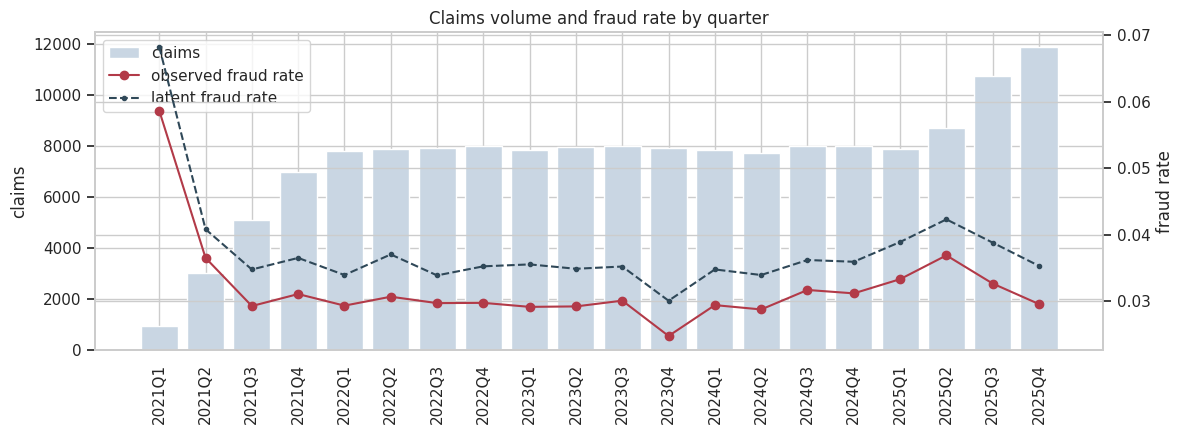

In [13]:

features["flag_early_claim"] = features["days_since_policy_start"] <= 60
features["flag_late_report"] = features["report_delay_days"] > 14
features["flag_theft_no_police"] = (
    (features["incident_type_clean"] == "theft")
    & (features["police_report_filed"].fillna(1) == 0)
)
features["flag_large_ratio"] = features["claim_to_sum_insured_ratio"] > 0.8
features["flag_prior_3"] = features["prior_claims_12m"] >= 3
features["flag_night"] = features["incident_hour"].fillna(-1).between(0, 4)
features["flag_non_authorized"] = features["is_authorized_workshop"] == 0
features["flag_overvalued"] = (
    (features["vehicle_age_years"] >= 7)
    & ((features["sum_insured"] / features["vehicle_value"]) > 1.02)
)
features["flag_online_new"] = (
    (features["sales_channel_clean"] == "online")
    & (features["customer_tenure_months"] < 6)
)
features["flag_early_large"] = (
    features["flag_early_claim"] & (features["claim_to_sum_insured_ratio"] > 0.5)
)

signal_rows = []
for name, flag in {
    "early claim (<=60d)": features["flag_early_claim"],
    "report delay > 14d": features["flag_late_report"],
    "theft without police report": features["flag_theft_no_police"],
    "claim / sum insured > 0.8": features["flag_large_ratio"],
    "3+ claims in prior 12m": features["flag_prior_3"],
    "incident hour 00-04": features["flag_night"],
    "non-authorized workshop": features["flag_non_authorized"],
    "overvaluation (age>=7, SI/value>1.02)": features["flag_overvalued"],
    "online + tenure < 6m": features["flag_online_new"],
    "early x large claim": features["flag_early_large"],
}.items():
    flag = flag.fillna(False).astype(bool)
    signal_rows.append({
        "signal": name,
        "claims": int(flag.sum()),
        "share": float(flag.mean()),
        "fraud_rate": float(features.loc[flag, "is_fraud"].mean()),
        "lift": float(features.loc[flag, "is_fraud"].mean() / observed_rate),
    })

signal_table = pd.DataFrame(signal_rows).sort_values("lift", ascending=False)
display(signal_table)

features["quarter"] = features["incident_date"].dt.to_period("Q").astype(str)
quarterly = features.groupby("quarter").agg(
    claims=("claim_id", "size"),
    fraud_rate=("is_fraud", "mean"),
    latent_fraud_rate=("true_fraud", "mean"),
).reset_index()

fig, ax1 = plt.subplots(figsize=(12, 4.5))
ax1.bar(quarterly["quarter"], quarterly["claims"], color="#c9d6e3", label="claims")
ax1.set_ylabel("claims")
ax1.tick_params(axis="x", rotation=90)
ax2 = ax1.twinx()
ax2.plot(quarterly["quarter"], quarterly["fraud_rate"], color="#b23a48", marker="o", label="observed fraud rate")
ax2.plot(quarterly["quarter"], quarterly["latent_fraud_rate"], color="#2f4858", linestyle="--", marker=".", label="latent fraud rate")
ax2.set_ylabel("fraud rate")
ax1.set_title("Claims volume and fraud rate by quarter")
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper left")
plt.tight_layout()
plt.show()



### 10.3 Fraud rate by category and by workshop

The workshop table is where the hidden ring becomes visible to an analyst: a small number of workshops combine high claim volume with a fraud rate several times the portfolio average. `ring_truth` is shown only because this is a synthetic-data diagnostic. It is not a model feature.


In [14]:

for column in ["incident_type_clean", "sales_channel_clean", "coverage_type_clean"]:
    table = (
        features.groupby(column)
        .agg(claims=("claim_id", "size"), fraud_rate=("is_fraud", "mean"))
        .sort_values("fraud_rate", ascending=False)
    )
    table["lift"] = table["fraud_rate"] / observed_rate
    print(f"\nFraud rate by {column}")
    display(table)

workshop_stats = features.groupby("workshop_id").agg(
    claims=("claim_id", "size"),
    fraud_rate=("is_fraud", "mean"),
    authorized=("is_authorized_workshop", "max"),
)
ring_map = features.groupby("workshop_id")["ring_era"].agg(
    lambda values: values.dropna().iloc[0] if values.notna().any() else "none"
)
workshop_stats["ring_truth"] = ring_map.reindex(workshop_stats.index).to_numpy()
workshop_stats["lift"] = workshop_stats["fraud_rate"] / observed_rate

print("\nWorkshops with at least 200 claims, sorted by fraud rate")
display(
    workshop_stats.loc[workshop_stats["claims"] >= 200]
    .sort_values("fraud_rate", ascending=False)
    .head(15)
)

print("\nRing vs non-ring (truth is for analysis only)")
display(
    features.assign(ring_group=features["ring_era"].fillna("none"))
    .groupby("ring_group")
    .agg(
        claims=("claim_id", "size"),
        fraud_rate=("is_fraud", "mean"),
        latent_fraud_rate=("true_fraud", "mean"),
        mean_workshop_claims_90d=("workshop_claim_count_90d", "mean"),
    )
)



Fraud rate by incident_type_clean


,claims,fraud_rate,lift
incident_type_clean,,,
theft,24417,0.0576,1.8766
fire,14166,0.0330,1.0759
flood,15143,0.0254,0.8280
collision,81968,0.0244,0.7938
vandalism,14306,0.0243,0.7922



Fraud rate by sales_channel_clean


,claims,fraud_rate,lift
sales_channel_clean,,,
online,48639,0.0361,1.1744
agent,71066,0.0282,0.9170
broker,30295,0.0281,0.9148



Fraud rate by coverage_type_clean


,claims,fraud_rate,lift
coverage_type_clean,,,
tlo,65424,0.0312,1.0174
comprehensive,84576,0.0303,0.9865



Workshops with at least 200 claims, sorted by fraud rate


,claims,fraud_rate,authorized,ring_truth,lift
workshop_id,,,,,
W0304,366,0.1667,0,new,5.4277
W0303,386,0.1295,0,new,4.2184
W0267,814,0.1179,0,old,3.8407
W0283,876,0.1176,0,old,3.8291
W0124,945,0.1164,1,old,3.7908
W0302,377,0.1034,1,new,3.3689
W0301,343,0.0933,1,new,3.0382
W0002,891,0.0864,1,old,2.8144
W0268,821,0.0828,1,old,2.6973



Ring vs non-ring (truth is for analysis only)


,claims,fraud_rate,latent_fraud_rate,mean_workshop_claims_90d
ring_group,,,,
new,1472,0.1236,0.1481,81.3010
none,139827,0.0260,0.0306,25.3454
old,8701,0.0908,0.1053,46.8971



### 10.4 The leakage trap, quantified

If `siu_investigation_flag`, `payout_amount`, or `claim_status` enter a model, the model learns **how claims were processed**, not how fraud looks at intake. This is the difference between data available when a claim is submitted and data available weeks later.

The rule below is intentionally naive, but it shows the size of the leak: investigated or zero-payout claims capture nearly every labelled fraud.


In [15]:

print("Fraud rate by SIU investigation flag")
display(
    features.groupby("siu_investigation_flag").agg(
        claims=("claim_id", "size"),
        fraud_rate=("is_fraud", "mean"),
        latent_fraud_rate=("true_fraud", "mean"),
        mean_payout=("payout_amount", "mean"),
    )
)

print("\nFraud rate by claim status")
display(
    features.groupby("claim_status_clean").agg(
        claims=("claim_id", "size"),
        fraud_rate=("is_fraud", "mean"),
        latent_fraud_rate=("true_fraud", "mean"),
        share_zero_payout=("payout_amount", lambda values: float((values == 0).mean())),
    ).sort_values("fraud_rate", ascending=False)
)

leak_rule = features["siu_investigation_flag"].eq(1) | features["payout_amount"].eq(0)
leak_table = pd.DataFrame({
    "quantity": [
        "claims flagged by leak rule",
        "share of all claims",
        "fraud rate among flagged",
        "share of labelled fraud captured (recall)",
        "share of flagged claims that are legitimate",
    ],
    "value": [
        f"{int(leak_rule.sum()):,}",
        f"{leak_rule.mean():.4f}",
        f"{features.loc[leak_rule, 'is_fraud'].mean():.4f}",
        f"{features.loc[leak_rule, 'is_fraud'].sum() / features['is_fraud'].sum():.4f}",
        f"{1 - features.loc[leak_rule, 'is_fraud'].mean():.4f}",
    ],
})
display(leak_table)
print("These columns must be dropped before training. They are outcomes, not predictors.")


Fraud rate by SIU investigation flag


,claims,fraud_rate,latent_fraud_rate,mean_payout
siu_investigation_flag,,,,
0,142813,0.0016,0.0072,"49,610,326.1118"
1,7187,0.6082,0.6099,"18,487,053.1515"



Fraud rate by claim status


,claims,fraud_rate,latent_fraud_rate,share_zero_payout
claim_status_clean,,,,
rejected,12150,0.2848,0.2900,1.0000
under_review,7022,0.1632,0.1690,1.0000
approved,130828,0.0000,0.0054,0.0000


,quantity,value
0,claims flagged by leak rule,"21,691"
1,share of all claims,0.1446
2,fraud rate among flagged,0.2123
3,share of labelled fraud captured (recall),1.0000
4,share of flagged claims that are legitimate,0.7877


These columns must be dropped before training. They are outcomes, not predictors.



### 10.5 Time drift in 2025

Two things change in 2025:

1. Part of the fraud ring moves to four workshops opened on 2025-01-01; the old ring's odds are dampened.
2. The online-channel effect is multiplied by 1.55.

A model trained on 2021-2023 should therefore see a different channel mix and a different workshop mix on the test period. That is the intended material for a drift-monitoring discussion.


sales_channel_clean,agent,broker,online
year,,,
2021,0.0314,0.0332,0.0368
2022,0.0281,0.0262,0.0362
2023,0.0259,0.0270,0.0328
2024,0.0292,0.0267,0.0336
2025,0.0278,0.0295,0.0397


sales_channel_clean,agent,broker,online
year,,,
2021,8568,3557,3913
2022,16321,6825,8458
2023,15333,6517,9837
2024,14251,6206,11083
2025,16593,7190,15348


ring_group,new,none,old
year,,,
2021,NaN,0.0289,0.0927
2022,NaN,0.0250,0.0947
2023,NaN,0.0233,0.1007
2024,NaN,0.0252,0.1018
2025,0.1236,0.0285,0.0492


ring_group,new,none,old
year,,,
2021,0.0000,"14,992.0000","1,046.0000"
2022,0.0000,"29,398.0000","2,206.0000"
2023,0.0000,"29,632.0000","2,055.0000"
2024,0.0000,"29,447.0000","2,093.0000"
2025,"1,472.0000","36,358.0000","1,301.0000"


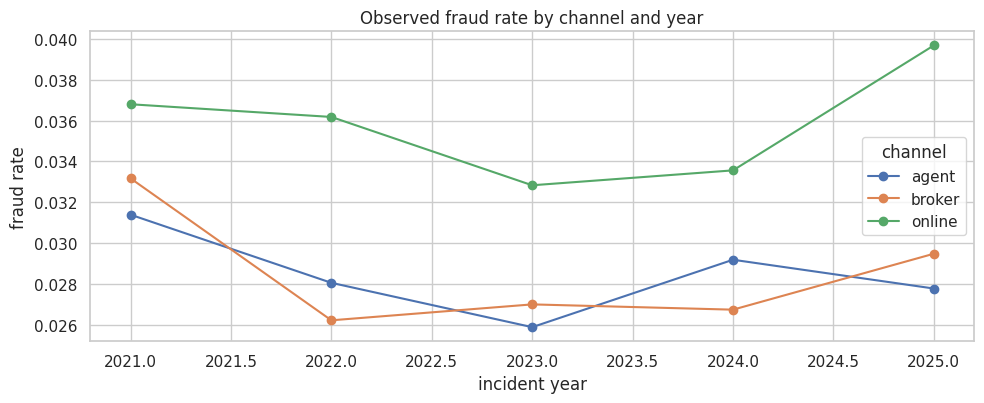

In [16]:

features["year"] = features["incident_date"].dt.year
features["ring_group"] = features["ring_era"].fillna("none")

channel_year = (
    features.groupby(["year", "sales_channel_clean"])
    .agg(claims=("claim_id", "size"), fraud_rate=("is_fraud", "mean"))
    .reset_index()
)
display(channel_year.pivot(index="year", columns="sales_channel_clean", values="fraud_rate"))
display(channel_year.pivot(index="year", columns="sales_channel_clean", values="claims").fillna(0))

ring_year = (
    features.groupby(["year", "ring_group"])
    .agg(claims=("claim_id", "size"), fraud_rate=("is_fraud", "mean"))
    .reset_index()
)
display(ring_year.pivot(index="year", columns="ring_group", values="fraud_rate"))
display(ring_year.pivot(index="year", columns="ring_group", values="claims").fillna(0))

fig, ax = plt.subplots(figsize=(10, 4.2))
for channel, group in channel_year.groupby("sales_channel_clean"):
    ax.plot(group["year"], group["fraud_rate"], marker="o", label=channel)
ax.set_title("Observed fraud rate by channel and year")
ax.set_xlabel("incident year")
ax.set_ylabel("fraud rate")
ax.legend(title="channel")
plt.tight_layout()
plt.show()



### 10.6 Fairness check

`age` and `province` are not generators of fraud in this synthetic world. Any difference below is sampling noise or an artefact of geography-linked workshop assignment. That is exactly why using them as predictors would be indefensible: the model would learn a proxy for where claims are processed, and in a real portfolio it could become profiling.

The optional diagnostic excludes both.


In [17]:

features["age_band"] = pd.cut(
    features["age"],
    bins=[17, 25, 35, 45, 55, 65, 75],
    labels=["18-25", "26-35", "36-45", "46-55", "56-65", "66-75"],
)
display(
    features.groupby("age_band", observed=True).agg(
        claims=("claim_id", "size"),
        fraud_rate=("is_fraud", "mean"),
        latent_fraud_rate=("true_fraud", "mean"),
    )
)
display(
    features.groupby("province").agg(
        claims=("claim_id", "size"),
        fraud_rate=("is_fraud", "mean"),
        latent_fraud_rate=("true_fraud", "mean"),
    ).sort_values("fraud_rate", ascending=False)
)


,claims,fraud_rate,latent_fraud_rate
age_band,,,
18-25,22690,0.0301,0.0360
26-35,40055,0.0309,0.0359
36-45,47510,0.0305,0.0361
46-55,28892,0.0307,0.0360
56-65,9256,0.0325,0.0379
66-75,1597,0.0301,0.0369


,claims,fraud_rate,latent_fraud_rate
province,,,
Sumatera Selatan,5925,0.0459,0.0540
Sumatera Barat,4497,0.0436,0.0498
Banten,11957,0.0343,0.0405
Jawa Barat,25488,0.0334,0.0397
Jawa Timur,21261,0.0312,0.0370
Jawa Tengah,17730,0.0296,0.0330
Sumatera Utara,10364,0.0283,0.0338
DKI Jakarta,27113,0.0282,0.0336
Kalimantan Timur,4493,0.0260,0.0294



### 10.7 Data-quality checks

These are the defects that make the cleaning stage meaningful. A production pipeline should decide, explicitly, whether to deduplicate, clip, impute, or drop.


,check,value
0,raw rows,150300
1,raw duplicate claim_id rows,300
2,raw fully duplicated rows,300
3,negative report delay rows,450
4,claim amount above sum insured,4763
5,claims before policy start,0
6,missing witness_count,0.0537
7,missing police_report_filed,0.0427
8,missing incident_hour,0.0542
9,raw incident_type variants,10


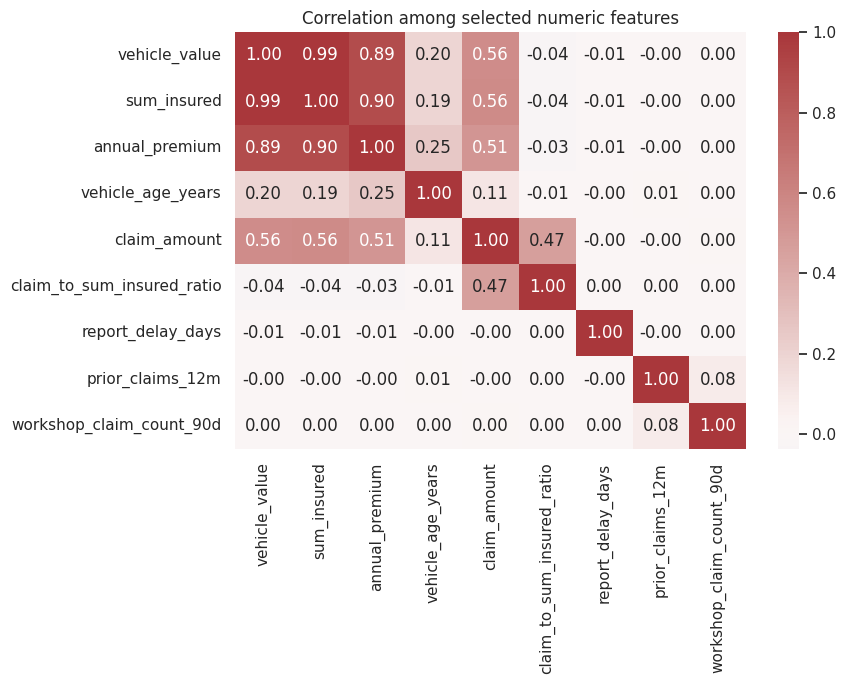

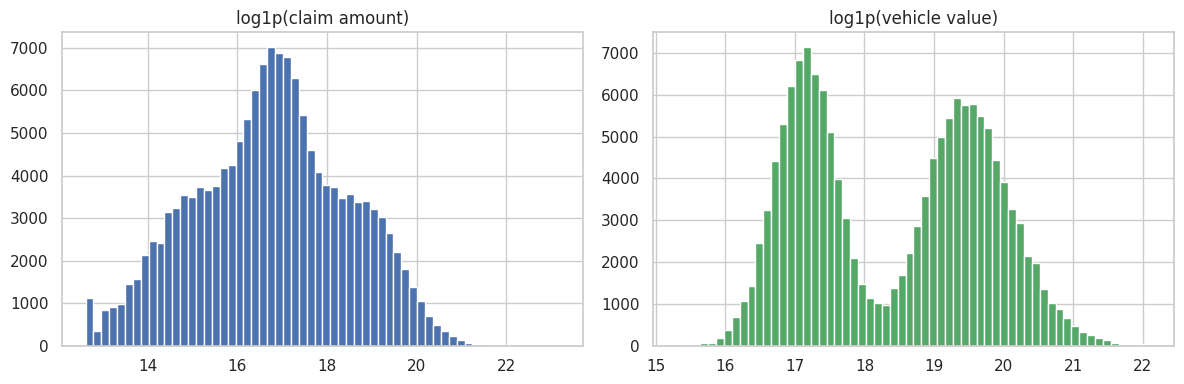

In [18]:

quality_rows = [
    ("raw rows", len(claims)),
    ("raw duplicate claim_id rows", int(claims.duplicated("claim_id").sum())),
    ("raw fully duplicated rows", int(claims.duplicated().sum())),
    ("negative report delay rows", int((features["report_delay_days"] < 0).sum())),
    ("claim amount above sum insured", int((features["claim_amount"] > features["sum_insured"]).sum())),
    ("claims before policy start", int((features["days_since_policy_start"] < 0).sum())),
    ("missing witness_count", f"{features['witness_count'].isna().mean():.4f}"),
    ("missing police_report_filed", f"{features['police_report_filed'].isna().mean():.4f}"),
    ("missing incident_hour", f"{features['incident_hour'].isna().mean():.4f}"),
    ("raw incident_type variants", int(features["incident_type"].nunique())),
    ("clean incident_type variants", int(features["incident_type_clean"].nunique())),
    ("raw claim_status variants", int(features["claim_status"].nunique())),
    ("clean claim_status variants", int(features["claim_status_clean"].nunique())),
]
display(pd.DataFrame(quality_rows, columns=["check", "value"]))

correlation_columns = [
    "vehicle_value", "sum_insured", "annual_premium", "vehicle_age_years",
    "claim_amount", "claim_to_sum_insured_ratio", "report_delay_days",
    "prior_claims_12m", "workshop_claim_count_90d",
]
correlation = features[correlation_columns].corr()
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(correlation, annot=True, fmt=".2f", cmap="vlag", center=0, ax=ax)
ax.set_title("Correlation among selected numeric features")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(np.log1p(features["claim_amount"]), bins=60, color="#4c72b0")
axes[0].set_title("log1p(claim amount)")
axes[1].hist(np.log1p(features["vehicle_value"]), bins=60, color="#55a868")
axes[1].set_title("log1p(vehicle value)")
plt.tight_layout()
plt.show()



## 11. Optional appendix: fixed-config difficulty diagnostic

This is **optional** and is not part of the generator or the EDA. It is here only to check whether the locked configuration lands in the intended difficulty band:

| Model | Target PR-AUC on synthetic data |
|---|---|
| Logistic regression | 0.20 to 0.35 |
| Gradient boosting | 0.35 to 0.55 |

Rules for using this cell honestly:

- No leakage columns. No `true_fraud`, no `ring_era`, no `claim_status`, no `payout_amount`, no `siu_investigation_flag`, no `days_to_settlement`.
- No `age`, no customer `province`, and no `incident_province`. Geography is not used as a fraud predictor in this diagnostic.
- No `n_policies_total`: it is a full-period snapshot and would be a mild future leak for an early claim. The same caution applies to `customer_tenure_months_snapshot`; neither is used.
- No hyperparameter search and no generator iteration. Run once, report what you see, and stop.
- PR-AUC is evaluated on the raw observed label, which contains 15% label noise. That noise caps the achievable score.

If the numbers fall outside the ranges, document the result rather than tuning the generator against the test set. Tuning a synthetic generator until the model looks good is a subtle form of cheating.


In [19]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import average_precision_score, roc_auc_score

NUMERIC_FEATURES = [
    "customer_tenure_months", "vehicle_age_years",
    "vehicle_value", "sum_insured", "annual_premium", "incident_hour",
    "claim_amount", "witness_count", "prior_claims_12m", "prior_claims_total",
    "report_delay_days", "days_since_policy_start",
    "claim_to_sum_insured_ratio", "claim_to_premium_ratio",
    "workshop_claim_count_90d", "police_report_filed",
    "is_authorized_workshop",
]
CATEGORICAL_FEATURES = [
    "occupation_group_clean", "coverage_type_clean", "vehicle_type",
    "sales_channel_clean", "payment_frequency_clean", "incident_type_clean",
]
MODEL_FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES

model_frame = features.copy()
model_frame[CATEGORICAL_FEATURES] = (
    model_frame[CATEGORICAL_FEATURES].fillna("missing").astype(str)
)

train = model_frame[model_frame["split"] == "train"]
validation = model_frame[model_frame["split"] == "validation"]
test = model_frame[model_frame["split"] == "test"]


def make_preprocessor():
    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    return ColumnTransformer([
        ("numeric", numeric_pipeline, NUMERIC_FEATURES),
        ("categorical", categorical_pipeline, CATEGORICAL_FEATURES),
    ])


estimators = {
    "logistic regression": LogisticRegression(max_iter=2000, solver="lbfgs"),
    "hist gradient boosting": HistGradientBoostingClassifier(
        max_iter=300,
        learning_rate=0.06,
        max_leaf_nodes=31,
        l2_regularization=1.0,
        random_state=CONFIG["seed"],
    ),
}

diagnostic_rows = []
for name, estimator in estimators.items():
    pipeline = Pipeline([
        ("preprocessor", make_preprocessor()),
        ("model", estimator),
    ])
    pipeline.fit(train[MODEL_FEATURES], train["is_fraud"].astype(int))
    for split_name, part in [("validation", validation), ("test", test)]:
        probabilities = pipeline.predict_proba(part[MODEL_FEATURES])[:, 1]
        diagnostic_rows.append({
            "model": name,
            "split": split_name,
            "rows": len(part),
            "positives": int(part["is_fraud"].sum()),
            "prevalence": float(part["is_fraud"].mean()),
            "pr_auc": float(average_precision_score(part["is_fraud"], probabilities)),
            "roc_auc": float(roc_auc_score(part["is_fraud"], probabilities)),
        })

display(pd.DataFrame(diagnostic_rows))
display(pd.DataFrame({
    "model": ["logistic regression", "hist gradient boosting"],
    "target_pr_auc": ["0.20 - 0.35", "0.35 - 0.55"],
}))


,model,split,rows,positives,prevalence,pr_auc,roc_auc
0,logistic regression,validation,15555,452,0.0291,0.0811,0.6990
1,logistic regression,test,55116,1784,0.0324,0.0855,0.6875
2,hist gradient boosting,validation,15555,452,0.0291,0.1068,0.7514
3,hist gradient boosting,test,55116,1784,0.0324,0.0983,0.7259


,model,target_pr_auc
0,logistic regression,0.20 - 0.35
1,hist gradient boosting,0.35 - 0.55



## 12. What this dataset does not represent

- Real fraud behaviour. The model can only recover the planted odds ratios, interactions, and ring effect.
- Claim frequency or exposure. About 1.5 claims per policy is an assumption, not a calibrated frequency model.
- Real pricing. Premiums are a simple rate applied to sum insured with noise.
- Real investigation. Detection is a constant 85%; real SIU triage is selective and correlated with claim size, channel, and geography.
- Real text. There is no claim narrative. A TF-IDF model on templated text would learn the template, so text is deliberately out of scope.
- Real geography or demographics. Province and occupation are labels, not a portfolio.

## 13. Suggested next steps

1. Build a separate modelling notebook that reads `claims.parquet`, `policies.parquet`, and `customers.parquet`.
2. Drop the four post-processing columns before any split. Write the reason in the model card.
3. Split by incident date, never at random: train 2021-2023, validate 2024 H1, test 2024 H2-2025.
4. Choose the threshold from a cost matrix, not from F1 alone. Missing fraud and blocking a legitimate claim have different costs.
5. Monitor the 2025 channel mix and workshop mix. A drop in PR-AUC with a stable ROC-AUC usually means prevalence or ranking changed, not that the model broke.
6. Report every metric with the label **"synthetic data"** and the generator seed.

## 14. Reproducibility

`generator_config.json` records the locked configuration, calibrated intercept, row counts, and observed rates. `manifest.json` records library versions and file sizes. Re-running the notebook from top to bottom with the same seed reproduces the tables byte-for-byte apart from the `generated_at_utc` timestamp.

The truth file is written to `claims_truth.parquet` directly inside `data/`. It exists for error analysis and for checking label noise. Never join it into model features.
